**STAGE 10. A NEURAL NETWORK FOR REGRESSION (Colab)**

- QUESTION: Can the Day 13 to 17 machine predict a price, and does it beat the classical models?
- CHECK: Rebuilt the data (feature set A, 302 columns), inner split 80/20, imputer and scaler fitted on the inner train part only, standardised target; Dataset and DataLoader; a 302-64-32-1 network with MSELoss and AdamW; pre-flight check; four runs, one change at a time, with early stopping (patience 20); all models scored on the same 234 validation rows.
- FINDING: An untrained network scores about 1.1 on the standardised target, close to the mean-predictor (1.0142), so the pipeline is correct. Without target scaling the network fails (RMSE about 1.1 on the log price). The plain network reaches its best epoch at 11 and then memorises (train MSE 0.033, validation 0.103). Dropout moves the best epoch to 22 and dropout 0.5 plus weight decay to 51, but the gain in RMSE_log is only 0.001 (0.1255 to 0.1244), inside the noise of a 234-row split.
- DECISION: For this data a neural network is not worth the extra work, because it ends in the same neighbourhood as Ridge (0.1244 against 0.1214) and XGBoost (0.1206), while needing target scaling, a training loop, early stopping and a seed. The network does not enter Stage 11, since it was not scored on the same folds.

| run | best epoch | stopped | train MSE | val MSE | RMSE_log |
|---|---|---|---|---|---|
| (a) plain | 11 | 31 | 0.0326 | 0.1034 | 0.1255 |
| (b) dropout 0.3 | 22 | 42 | 0.0982 | 0.1020 | 0.1246 |
| (c) dropout 0.5 + wd 0.1 | 51 | 71 | 0.1403 | 0.1016 | 0.1244 |
| (d) small 16-8 | 20 | 40 | 0.0311 | 0.1048 | 0.1263 |

| model (same 234 rows) | RMSE_log |
|---|---|
| XGBoost | 0.1206 |
| Ridge | 0.1214 |
| Best network (c) | 0.1244 |
| Forest | 0.1337 |

- S10-1  Output layer: nn.Linear(32, 1). No ReLU or softmax after it. Loss: nn.MSELoss. Labels: dtype float32, shape (N, 1) (Day 16 classification labels were int64, shape (N,)).
- S10-2  Inner split: train 932 rows, validation 234 rows. Target mean = 12.0331, std = 0.3902 (computed from the inner train part only).
- S10-3  Untrained validation MSE (standardised target) = about 1.14; mean-predictor MSE = 1.0142. A trained network must go clearly below 1.0.
- S10-4  The trap: untrained MSE on the raw log price = about 139 (about 12 x 12). The raw-target run ends with RMSE about 1.1, a failure, because it first has to learn that the average log price is about 12.
- S10-5  RMSE_log = sqrt(MSE) x 0.3902 (the target std). Dollars from a scaled prediction: np.expm1(pred_scaled x std + mean).
- S10-6  The run table above.
- S10-7  Run (a) stopped at epoch 31 because its best epoch was 11 and the patience was 20. Its validation loss after the best epoch rose.
- S10-8  Same 234 rows: Ridge 0.1214; forest 0.1337; XGBoost 0.1206; best network 0.1244. My ranking: XGBoost, Ridge and the network are tied, the forest is behind. Differences smaller than about 0.005 cannot be ranked with one split of 234 rows.
- S10-9  The network is not allowed to enter Stage 11's choice, because it was not scored with the same 5 folds as the others. To include it fairly I would have to train it once per fold of the same KFold and compare the mean and std.
- S10-10 Helped most: dropout 0.3 (best epoch 11 to 22), and early stopping, which every run uses. Did nothing measurable: the extra weight decay in run (c), since its 0.0002 extra gain is noise and I changed it together with dropout 0.5.

In [106]:
import copy, numpy as np, pandas as pd, torch, torch.nn as nn, matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [107]:
df = pd.read_csv("train.csv")
y = np.log1p(df["SalePrice"].to_numpy())
X = df.drop(columns=["Id", "SalePrice"])
X["MSSubClass"] = X["MSSubClass"].astype(str)
txt = X.select_dtypes(exclude="number").columns
X[txt] = X[txt].fillna("None")
X = pd.get_dummies(X, dtype=float)
print(X.shape)

(1460, 317)


In [112]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2, random_state=42
)
bad = (Xtr["GrLivArea"] > 4000) & (np.expm1(ytr) < 300000)
Xtr, ytr = Xtr[~bad], ytr[~bad.to_numpy()]
cols = [c for c in Xtr.columns if c.startswith(("SaleType", "SaleCondition"))]
Xtr = Xtr.drop(columns=cols)

Xa, Xv, ya, yv = train_test_split(
    Xtr, ytr, test_size=0.2, random_state=42
)
print(Xa.shape, Xv.shape)

(932, 302) (234, 302)


In [113]:
imp = SimpleImputer(strategy="median")
sc = StandardScaler().fit(imp.fit_transform(Xa))
Ta = sc.transform(imp.transform(Xa))
Tv = sc.transform(imp.transform(Xv))
ym, ys  = ya.mean(), ya.std()
ya_s = (ya - ym) / ys
yv_s = (yv - ym) / ys
print(round(ym, 4), round(ys, 4))

12.0331 0.3902


In [118]:
class HouseDS(Dataset):
  def __init__(self, X, y):
    self.X = torch.tensor(X, dtype=torch.float32)
    self.y = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

  def __len__(self):
    return len(self.X)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

def new_train_loader(y_lab):
  return DataLoader(HouseDS(Ta, y_lab), batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))

xb, yb = next(iter(new_train_loader(ya_s)))
print(xb.shape, yb.shape)

torch.Size([64, 302]) torch.Size([64, 1])


In [121]:
n_in = Ta.shape[1]
def mk(h1=64, h2=32, p=0.0):
  torch.manual_seed(42)
  layers = [nn.Linear(n_in, h1), nn.ReLU()]
  if p > 0: layers.append(nn.Dropout(p))
  layers += [nn.Linear(h1, h2), nn.ReLU()]
  if p > 0: layers.append(nn.Dropout(p))
  layers.append(nn.Linear(h2, 1))
  return nn.Sequential(*layers)

In [125]:
loss_fn = nn.MSELoss()
m0 = mk()
m0.eval()
with torch.no_grad():
  pred0 = m0(torch.tensor(Tv, dtype=torch.float32))
  u = loss_fn(pred0, torch.tensor(yv_s, dtype=torch.float32).reshape(-1, 1)).item()
  u_raw = loss_fn(pred0, torch.tensor(yv, dtype=torch.float32).reshape(-1, 1)).item()

print("untrained:", round(u, 4), "| mean-predictor:", round(float(np.mean(yv_s ** 2)), 4))
print("untrained on the RAW log price:", round(u_raw, 1))

untrained: 1.136 | mean-predictor: 1.0142
untrained on the RAW log price: 139.2


In [130]:
def train_run(model, epochs=200, lr=1e-3, wd=0.0, patience=20, scale_y=True):
  ytrn = ya_s if scale_y else ya
  yval = yv_s if scale_y else yv
  tl = new_train_loader(ytrn)
  vl = DataLoader(HouseDS(Tv, yval), batch_size=256)
  opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
  best, best_ep, best_state, wait, hist = 1e9, 0, None, 0, []
  for ep in range(1, epochs + 1):
    model.train()
    tot = n = 0
    for xb, yb in tl:
      opt.zero_grad()
      loss = loss_fn(model(xb), yb)
      loss.backward()
      opt.step()
      tot += loss.item() * len(xb); n += len(xb)
    model.eval()
    vt = vn = 0
    with torch.no_grad():
      for xb, yb in vl:
        vt += loss_fn(model(xb), yb).item() * len(xb); vn += len(xb)
    v = vt / vn; hist.append(v)
    if v < best:
      best, best_ep, wait, tr_best = v, ep, 0, tot/n
      best_state = copy.deepcopy(model.state_dict())
    else:
      wait += 1
      if wait >= patience: break
  model.load_state_dict(best_state)
  return best, best_ep, ep, tr_best, hist

In [131]:
b, be, last, tr, h = train_run(mk(), scale_y=False)
print("raw target best val mse:", round(b, 3), "| RMSE", round(b ** 0.5, 3), "| best epoch", be)

raw target best val mse: 1.24 | RMSE 1.114 | best epoch 102


In [137]:
runs = [("plain",             dict(),        dict()),
        ("dropout 0.3",       dict(),        dict(p=0.3)),
        ("drop 0.5 + wd 0.1", dict(wd=0.1),  dict(p=0.5)),
        ("small 16-8",        dict(),        dict(h1=16, h2=8))]
rows, hist = [], {}
for name, tk, mk_kw in runs:
  b, be, last, tr, h = train_run(mk(**mk_kw), **tk)
  hist[name] = (h, be)
  rows.append((name, be, last, round(tr, 4), round(b, 4), round(b ** 0.5 * ys, 4)))
table = pd.DataFrame(rows, columns=["run", "best epoch", "stopped", "train MSE", "val MSE", "RMSE_log"])
table

,run,best epoch,stopped,train MSE,val MSE,RMSE_log
0,plain,11,31,0.0326,0.1034,0.1255
1,dropout 0.3,22,42,0.0982,0.1020,0.1246
2,drop 0.5 + wd 0.1,51,71,0.1403,0.1016,0.1244
3,small 16-8,20,40,0.0311,0.1048,0.1263


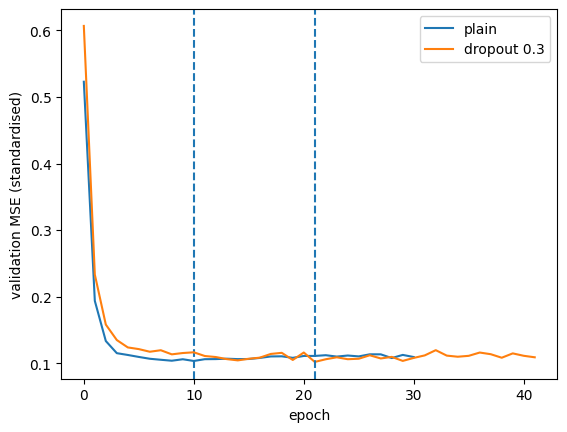

In [138]:
for name in ["plain", "dropout 0.3"]:
    h, be = hist[name]
    plt.plot(h, label=name)
    plt.axvline(be - 1, linestyle="--")             # the list starts at index 0, epochs at 1
plt.xlabel("epoch"); plt.ylabel("validation MSE (standardised)"); plt.legend(); plt.show()